<a href="https://colab.research.google.com/github/DanidDACC/-Redes-Neuronales-y-Deep-Learning-Proyecto-de-programaci-n-Deep-Vision-in-classification-tasks-/blob/main/07miar_deep_vision_proyecto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07MIAR - Redes Neuronales y Deep Learning: Proyecto de programación "*Deep Vision in classification tasks*"

### Comparación experimental: CNN desde cero vs Transfer Learning + Fine-Tuning

**Autores:**<br>
**Emilio Moreno Muñoz**<br>
**Angela Julieth Moreno**<br>
**Paola Andrea Sainea Molina**<br>
**Danid Alexander Camargo**

**Entorno:** Google Colab · Python · TensorFlow/Keras

> Este notebook está diseñado para ejecutar un proceso experimental reproducible. Las conclusiones se construyen únicamente a partir de métricas generadas por las ejecuciones.

## 0. Objetivo y diseño experimental

El objetivo de esta actividad es comparar de forma experimental dos estrategias de clasificación de imágenes sobre el conjunto de datos **CIFAR-10** (clasificación multiclase de 10 categorías):

1. **Entrenamiento desde cero (*from scratch*):** diseño y evolución progresiva de una red neuronal convolucional (CNN) propia, evaluando el impacto de la arquitectura, hiperparámetros, regularización y *data augmentation*.
2. **Transfer learning y *fine-tuning*:** adaptación de dos arquitecturas preentrenadas en ImageNet (**MobileNetV2** y **ResNet50**), analizando primero la extracción de características con la base congelada y posteriormente el ajuste fino (*fine-tuning*) selectivo/progresivo.

Para evitar filtración de datos (*data leakage*), se empleará un conjunto de **validación** para monitorizar el aprendizaje y guiar las decisiones experimentales, reservando el **conjunto de test** exclusivamente para la evaluación final imparcial.

In [ ]:
# Reproducibilidad
import os, random, time, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support, accuracy_score
SEED=42
os.environ['PYTHONHASHSEED']=str(SEED); random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: []


## 1. Carga e inspección del dataset

Se ha seleccionado **CIFAR-10** por tratarse de un benchmark clásico de clasificación multiclase con 10 categorías de objetos y animales en imágenes naturales a color de baja resolución (**32 × 32 × 3**), compuesto por **50.000 imágenes de entrenamiento** y **10.000 de prueba** (60.000 en total). Esta resolución reducida permite observar con claridad tanto las limitaciones y el sobreajuste al entrenar desde cero como los retos y ventajas de adaptar características aprendidas en imágenes de mayor resolución de ImageNet.

A continuación se comprueba el entorno de ejecución, se descarga y carga el conjunto de datos, y se analizan su dimensionalidad, balanceo de clases y ejemplos visuales.

In [ ]:
(x_train_all,y_train_all),(x_test,y_test)=keras.datasets.cifar10.load_data()
y_train_all=y_train_all.squeeze(); y_test=y_test.squeeze()
class_names=['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
print('Train original:',x_train_all.shape,'Test:',x_test.shape)
print('Dimensión:',x_train_all.shape[1:],'Clases:',len(class_names))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1482s 9us/step
Train original: (50000, 32, 32, 3) Test: (10000, 32, 32, 3)
Dimensión: (32, 32, 3) Clases: 10


,clase,n
0,airplane,5000
1,automobile,5000
2,bird,5000
3,cat,5000
4,deer,5000
5,dog,5000
6,frog,5000
7,horse,5000
8,ship,5000
9,truck,5000


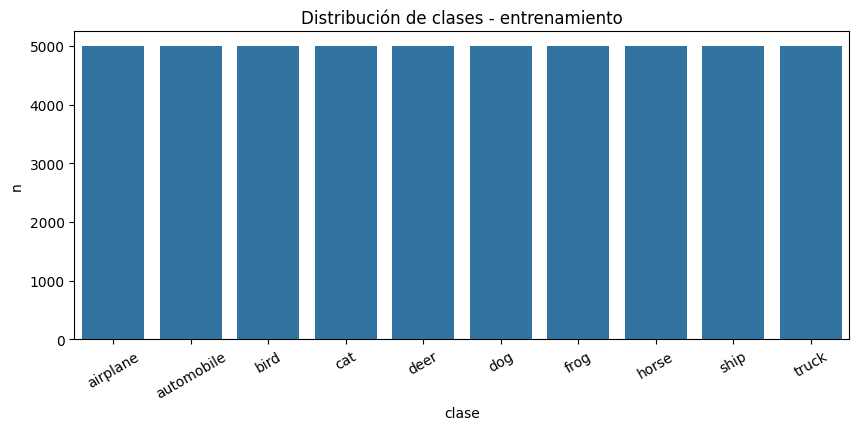

In [ ]:
# Distribución de clases
counts=pd.Series(y_train_all).value_counts().sort_index()
df_dist=pd.DataFrame({'clase':class_names,'n':counts.values})
display(df_dist)
plt.figure(figsize=(10,4)); sns.barplot(data=df_dist,x='clase',y='n'); plt.xticks(rotation=30); plt.title('Distribución de clases - entrenamiento'); plt.show()

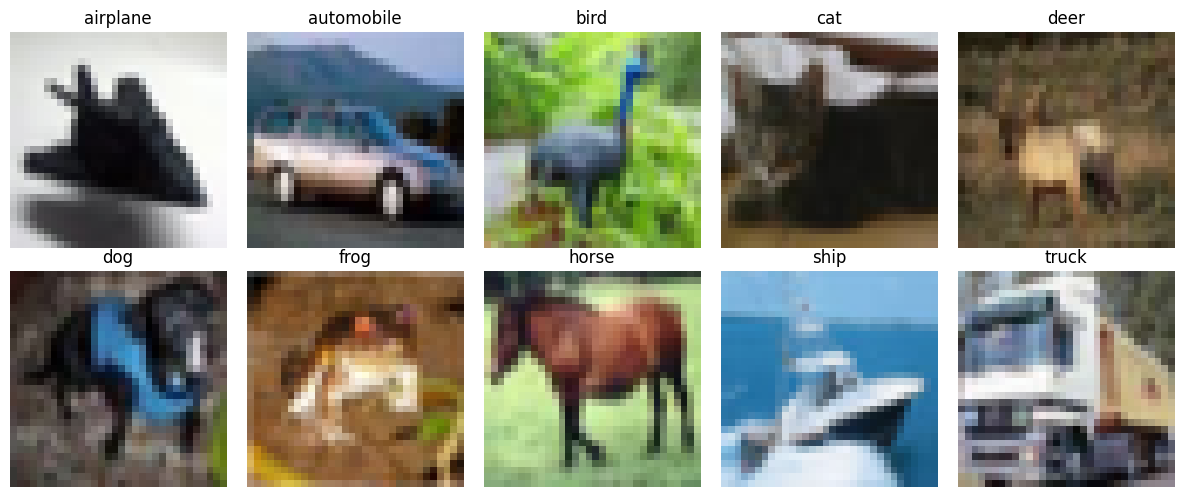

In [ ]:
# Muestras visuales
fig,axes=plt.subplots(2,5,figsize=(12,5))
for k,ax in enumerate(axes.flat):
    idx=np.where(y_train_all==k)[0][0]; ax.imshow(x_train_all[idx]); ax.set_title(class_names[k]); ax.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
#Validación de valores nulos en los datos de train y test
print("dtype:", x_train_all.dtype, "| min:", x_train_all.min(), "| max:", x_train_all.max())
print("NaN en train/test:", np.isnan(x_train_all).any(), np.isnan(x_test).any())
print("Distribución en test:", np.bincount(y_test)) # validamos que tengamos de diferentes clases y no tengamos desbalance en las muestras de nuestros datos de Test.

dtype: uint8 | min: 0 | max: 255
NaN en train/test: False False
Distribución en test: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


##INTERPRETACIÓN

Al cargar el Dataset se verifica que CIFAR-10 tiene 5.000 imágenes por clase en entrenamiento y 1.000 en prueba test (balanceado), también se evidencia que las imágenes de `32x32` tienen pixeles visibles y bajo detalle fino, por lo que clases como `cat`, `dog` o `deer` comparten fondos o siluetas parecidas, lo cual justifica probar distintas arquitecturas y técnicas de regularización más adelante.

### División de entrenamiento y validación
Se reserva el 20% del conjunto de entrenamiento como validación, con muestreo estratificado. El test original permanece completamente aislado hasta la evaluación final.

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_val,y_train,y_val=train_test_split(x_train_all,y_train_all,test_size=.20,stratify=y_train_all,random_state=SEED)
print(x_train.shape,x_val.shape,x_test.shape)

(40000, 32, 32, 3) (10000, 32, 32, 3) (10000, 32, 32, 3)


## 2. Preprocesamiento de datos

Para los modelos entrenados desde cero (**from scratch**), las imágenes (`uint8` en `[0, 255]`) se convierten a `float32` y se normalizan al rango `[0, 1]` para estabilizar el entrenamiento y evitar saturaciones o gradientes de magnitud desbalanceada. El aumento de datos (*data augmentation*) se evaluará de forma experimental en las iteraciones de la CNN desde cero (aplicándose **únicamente durante el entrenamiento** mediante transformaciones leves como volteo horizontal, pequeñas traslaciones y rotaciones).

Por otra parte, para las arquitecturas preentrenadas sobre ImageNet (**MobileNetV2** y **ResNet50**), el redimensionado desde `32 × 32` al tamaño de entrada requerido y la función `preprocess_input` específica de cada red se integrarán en su respectivo flujo de entrada para respetar la escala y representación con la que fueron entrenadas.

In [ ]:
BATCH = 128
def ds_scratch(x, y, shuffle=False):
  ds = tf.data.Dataset.from_tensor_slices((x.astype("float32") / 255.0, y))
  if shuffle:
    ds = ds.shuffle(len(x), seed=SEED)
  return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)


train_ds = ds_scratch(x_train, y_train, shuffle=True)
val_ds = ds_scratch(x_val, y_val, shuffle=False)
test_ds = ds_scratch(x_test, y_test, shuffle=False)

## 3. Estrategia 1: CNN desde cero

### Experimento 1.1: Modelo base (`baseline`)

Se parte de una arquitectura convolucional sencilla con tres bloques de `Conv2D(3x3)` con `32`, `64` y `128` filtros, `MaxPooling2D` y una capa densa de `128` neuronas antes de la salida *softmax* de 10 clases, sin aplicar *Batch Normalization*, *Dropout*, regularización L2 ni *data augmentation*.

El objetivo de este primer experimento es establecer una **línea base de referencia** para observar cómo aprende la red sobre imágenes de `32 × 32 × 3`, medir su tiempo de entrenamiento y detectar posibles problemas iniciales de subajuste (*underfitting*) o sobreajuste (*overfitting*).

In [ ]:
augment = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.06),
        layers.RandomTranslation(0.08, 0.08),
    ],
    name="data_augmentation",
)


def build_cnn(variant="baseline"):
  reg = regularizers.l2(1e-4) if variant == "full_reg_aug" else None
  use_bn_drop = variant in ("bn_dropout", "full_reg_aug")
  use_aug = variant == "full_reg_aug"

  inp = keras.Input(shape=(32, 32, 3))
  x = augment(inp) if use_aug else inp

  for f in [32, 64, 128]:
    x = layers.Conv2D(f, 3, padding="same", kernel_regularizer=reg)(x)
    if use_bn_drop:
      x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    if use_bn_drop:
      x = layers.Dropout(0.20)(x)

  x = layers.Flatten()(x)
  x = layers.Dense(128, activation="relu", kernel_regularizer=reg)(x)
  if use_bn_drop:
    x = layers.Dropout(0.40)(x)
  out = layers.Dense(10, activation="softmax")(x)

  model = keras.Model(inp, out, name=f"cnn_{variant}")
  model.compile(
      optimizer=keras.optimizers.Adam(1e-3),
      loss="sparse_categorical_crossentropy",
      metrics=["accuracy"],
  )
  return model


def make_callbacks():
  return [
      keras.callbacks.EarlyStopping(
          patience=5, restore_best_weights=True, monitor="val_loss"
      ),
      keras.callbacks.ReduceLROnPlateau(
          patience=2, factor=0.3, min_lr=1e-6, monitor="val_loss"
      ),
  ]


def run_exp(model, train_data, val_data, epochs=30):
  t0 = time.time()
  hist = model.fit(
      train_data,
      validation_data=val_data,
      epochs=epochs,
      callbacks=make_callbacks(),
      verbose=1,
  )
  return hist, time.time() - t0


def plot_history(h, title):
  fig, ax = plt.subplots(1, 2, figsize=(11, 4))
  ax[0].plot(h.history["accuracy"], label="train")
  ax[0].plot(h.history["val_accuracy"], label="val")
  ax[0].set_title(f"{title} - accuracy")
  ax[0].legend()
  ax[1].plot(h.history["loss"], label="train")
  ax[1].plot(h.history["val_loss"], label="val")
  ax[1].set_title(f"{title} - loss")
  ax[1].legend()
  plt.show()

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 24s 44ms/step - accuracy: 0.4305 - loss: 1.5730 - val_accuracy: 0.5439 - val_loss: 1.2736 - learning_rate: 0.0010
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.5854 - loss: 1.1668 - val_accuracy: 0.6217 - val_loss: 1.0728 - learning_rate: 0.0010
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.6521 - loss: 0.9884 - val_accuracy: 0.6723 - val_loss: 0.9509 - learning_rate: 0.0010
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6943 - loss: 0.8717 - val_accuracy: 0.6882 - val_loss: 0.8969 - learning_rate: 0.0010
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.7297 - loss: 0.7804 - val_accuracy: 0.6925 - val_loss: 0.8953 - learning_rate: 0.0010
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.7560 - loss: 0.7057 - val_accuracy: 0.7123 - val_loss: 0.8518 - learning_rate: 0.0010
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.7764 - loss: 0.6459

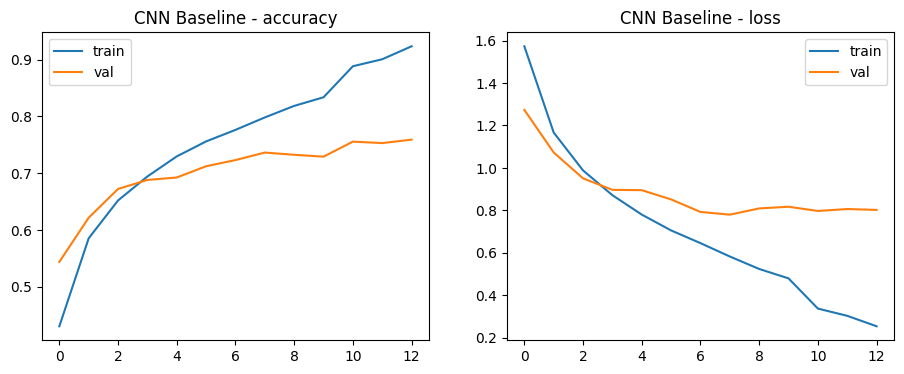

In [ ]:
m_base = build_cnn("baseline")
h_base, t_base = run_exp(m_base, train_ds, val_ds, epochs=30)
print(
    f"Tiempo baseline: {t_base:.1f}s | Mejor val_accuracy:"
    f" {max(h_base.history['val_accuracy']):.4f} | Menor val_loss:"
    f" {min(h_base.history['val_loss']):.4f}"
)
plot_history(h_base, "CNN Baseline")

**Análisis y decisión tras el Experimento 1.1 (`baseline`):**
- **Resultado obtenido:** el modelo base entrenó durante 13 épocas en **57.6 s**, alcanzando un mejor `val_accuracy` de **0.7592** y un `val_loss` mínimo de **0.7801**.
- **Diagnóstico:** a partir de las primeras épocas se observa una brecha creciente entre entrenamiento y validación: el *accuracy* de entrenamiento llega a **0.9236** y su *loss* baja hasta **0.2544**, mientras que `val_accuracy` no supera **0.7592** y `val_loss` deja de mejorar tras **0.7801**. Esto evidencia **sobreajuste (*overfitting*)**, lo cual es esperable en una red sin regularización sobre imágenes pequeñas (`32 × 32`).
- **Decisión para el siguiente experimento:** para frenar el sobreajuste y estabilizar el entrenamiento, en el **Experimento 1.2** se incorporan **Batch Normalization** y **Dropout** manteniendo la misma estructura base y los mismos *datasets* para comparar directamente.

### Experimento 1.2: Incorporación de Batch Normalization y Dropout

Aunque detener el entrenamiento en pocas épocas limitaría el avance del sobreajuste observado en el modelo base, hacerlo implicaría frenar el aprendizaje antes de alcanzar un mayor *accuracy* o un menor *loss* en validación. Por ello, en este segundo experimento se conservan los mismos bloques convolucionales (`32`, `64` y `128` filtros) y la capa densa (`128` neuronas), pero se incorporan **Batch Normalization** para estabilizar las distribuciones de activación entre capas y **Dropout** (`0.20` tras los bloques convolucionales y `0.40` antes de la capa de salida) para reducir la codependencia entre neuronas y mejorar la generalización.

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 147s 451ms/step - accuracy: 0.3249 - loss: 1.8199 - val_accuracy: 0.1696 - val_loss: 2.6706 - learning_rate: 0.0010
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 136s 434ms/step - accuracy: 0.4347 - loss: 1.5206 - val_accuracy: 0.5078 - val_loss: 1.4352 - learning_rate: 0.0010
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 135s 413ms/step - accuracy: 0.4851 - loss: 1.3931 - val_accuracy: 0.3712 - val_loss: 1.8663 - learning_rate: 0.0010
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 128s 409ms/step - accuracy: 0.5215 - loss: 1.3040 - val_accuracy: 0.6082 - val_loss: 1.1210 - learning_rate: 0.0010
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 131s 418ms/step - accuracy: 0.5403 - loss: 1.2544 - val_accuracy: 0.6013 - val_loss: 1.1285 - learning_rate: 0.0010
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 141s 413ms/step - accuracy: 0.5609 - loss: 1.2037 - val_accuracy: 0.4966 - val_loss: 1.3328 - learning_rate: 0.0010
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 143s 416ms/step - accura

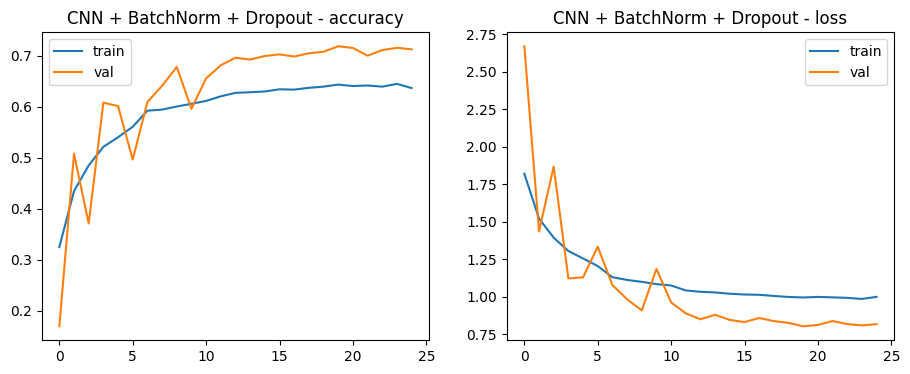

In [ ]:
m_bn_drop = build_cnn("bn_dropout")
h_bn_drop, t_bn_drop = run_exp(m_bn_drop, train_ds, val_ds, epochs=30)
print(
    f"Tiempo bn_dropout: {t_bn_drop:.1f}s | Mejor val_accuracy:"
    f" {max(h_bn_drop.history['val_accuracy']):.4f} | Menor val_loss:"
    f" {min(h_bn_drop.history['val_loss']):.4f}"
)
plot_history(h_bn_drop, "CNN + BatchNorm + Dropout")

**Análisis y decisión tras el Experimento 1.2 (`bn_dropout`):**
- **Comparación frente al baseline (`0.7592` val_accuracy / `0.7801` val_loss en `57.6 s`):** el modelo con *Batch Normalization* y *Dropout* entrenó durante 25 de las 30 épocas configuradas en **3408.2 s**, alcanzando un mejor `val_accuracy` de **0.7187** y un `val_loss` mínimo de **0.8018** (ambos en la época 20), quedando por debajo de las métricas del modelo base.
- **Diagnóstico:** se logra **eliminar el sobreajuste** del experimento anterior, ya que la pérdida de validación no diverge y el `val_accuracy` se mantiene por encima del *accuracy* de entrenamiento. Sin embargo, el aprendizaje se estanca alrededor de **0.6450** en entrenamiento (`loss` ~`0.9842`) y **0.7187** en validación (`val_loss` ~`0.8018`), reduciendo el *learning rate* hasta `2.43e-06`. Esto evidencia **subajuste (*underfitting*)**, ya que aplicar *Dropout* en cada bloque convolucional (`0.20`) junto con `0.40` en la capa densa sobre imágenes pequeñas (`32 × 32`) resulta demasiado restrictivo para la capacidad de la arquitectura.
- **Decisión para el siguiente experimento:** dado que el sobreajuste está controlado pero la regularización frena la capacidad de representación, en el **Experimento 1.3** se incorpora **data augmentation** (y regularización L2 ligera) suavizando el *Dropout* para mejorar la generalización y superar el `val_accuracy` del *baseline* manteniendo los mismos *datasets*.

### Experimento 1.3: Incorporación de Data Augmentation y regularización L2

Una vez controlado el sobreajuste mediante *Batch Normalization* y *Dropout*, en este tercer experimento se evalúa el efecto de incorporar **aumento de datos (*data augmentation*)** —volteo horizontal aleatorio (`RandomFlip`), rotaciones leves (`0.06`) y traslaciones pequeñas (`0.08`)— junto con una penalización L2 suave (`1e-4`) sobre los pesos. El objetivo es comprobar si aumentar la variabilidad visual durante el entrenamiento permite mejorar la generalización y superar el `val_accuracy` alcanzado en los experimentos previos.

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 22ms/step - accuracy: 0.2854 - loss: 1.9727 - val_accuracy: 0.1989 - val_loss: 2.3965 - learning_rate: 0.0010
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.3624 - loss: 1.7400 - val_accuracy: 0.4640 - val_loss: 1.5119 - learning_rate: 0.0010
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.3911 - loss: 1.6626 - val_accuracy: 0.5017 - val_loss: 1.3837 - learning_rate: 0.0010
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.4139 - loss: 1.6051 - val_accuracy: 0.5165 - val_loss: 1.3986 - learning_rate: 0.0010
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.4259 - loss: 1.5677 - val_accuracy: 0.4718 - val_loss: 1.4877 - learning_rate: 0.0010
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.4478 - loss: 1.5103 - val_accuracy: 0.4753 - val_loss: 1.4732 - learning_rate: 3.0000e-04
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.4541 - los

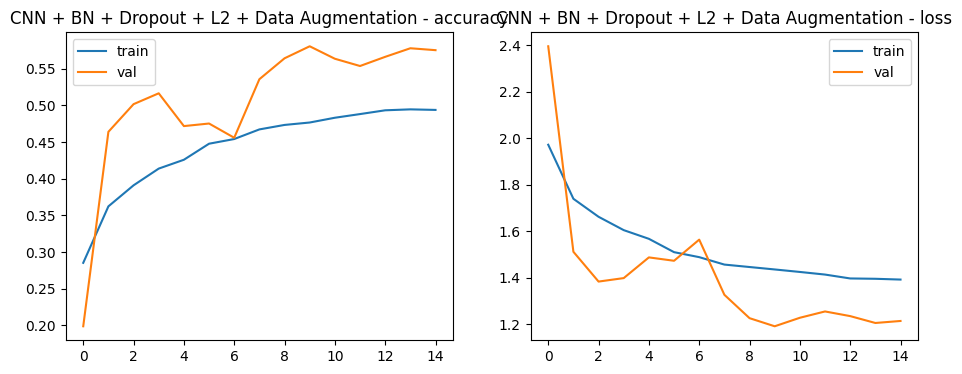

In [ ]:
m_reg_aug = build_cnn("full_reg_aug")
h_reg_aug, t_reg_aug = run_exp(m_reg_aug, train_ds, val_ds, epochs=30)
print(
    f"Tiempo full_reg_aug: {t_reg_aug:.1f}s | Mejor val_accuracy:"
    f" {max(h_reg_aug.history['val_accuracy']):.4f} | Menor val_loss:"
    f" {min(h_reg_aug.history['val_loss']):.4f}"
)
plot_history(h_reg_aug, "CNN + BN + Dropout + L2 + Data Augmentation")

**Análisis y decisión tras el Experimento 1.3 (`full_reg_aug`):**
- **Resultado obtenido:** el modelo entrenó 15 épocas en **103.6 s** (detenido por *EarlyStopping*), alcanzando un mejor `val_accuracy` de **0.5806** y un `val_loss` mínimo de **1.1912**.
- **Diagnóstico:** combinar *Batch Normalization*, *Dropout*, regularización L2 y *data augmentation* de forma simultánea en una CNN entrenada desde cero empeoró el rendimiento respecto a los pasos anteriores (`0.7592` en `baseline` y `0.7527` / `val_loss` de `0.7033` en `bn_dropout`). Al ser imágenes de baja resolución (`32 × 32`), rotarlas, desplazarlas o girarlas hace que pierdan claridad y que cueste más distinguir la clase, por lo que en una red pequeña desde cero —sumada a las demás restricciones de regularización— no mejora el aprendizaje sino que dificulta reconocer bien los patrones dentro de las épocas entrenadas (`0.4938` de *accuracy* en entrenamiento en la época 15).
- **Cierre de la Estrategia 1 (CNN desde cero):** se selecciona **`bn_dropout`** como la mejor opción dentro de esta estrategia por lograr el menor `val_loss` (**0.7033**) sin el sobreajuste marcado del modelo base, y se avanza a la **Estrategia 2 (*Transfer Learning* con `MobileNetV2` y `ResNet50`)** para ver si aprovechar pesos preentrenados en ImageNet supera estas limitaciones.

## 4. Estrategia 2: Transfer Learning
Se comparan **MobileNetV2** y **ResNet50**, ambas con pesos ImageNet. Primero se congela completamente el backbone. Después se realiza fine-tuning selectivo sobre las últimas capas con un learning rate bajo, reduciendo el riesgo de destruir representaciones preentrenadas.

In [ ]:
IMG = 96

augment_tl = keras.Sequential(
    [
        layers.Input(shape=(IMG, IMG, 3)),
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.06),
        layers.RandomTranslation(0.08, 0.08),
    ],
    name="augment_tl",
)
def make_transfer_data(preprocess):
    def prep(img,y):
        img=tf.image.resize(tf.cast(img,tf.float32),(IMG,IMG)); return preprocess(img),y
    def mk(x,y,tr=False):
        ds=tf.data.Dataset.from_tensor_slices((x,y));
        if tr: ds=ds.shuffle(len(x),seed=SEED)
        return ds.map(prep,num_parallel_calls=tf.data.AUTOTUNE).batch(64).prefetch(tf.data.AUTOTUNE)
    return mk(x_train,y_train,True),mk(x_val,y_val),mk(x_test,y_test)
def transfer_model(kind):
    if kind=='MobileNetV2': Base=keras.applications.MobileNetV2; prep=keras.applications.mobilenet_v2.preprocess_input
    else: Base=keras.applications.ResNet50; prep=keras.applications.resnet50.preprocess_input
    base=Base(weights='imagenet',include_top=False,input_shape=(IMG,IMG,3)); base.trainable=False
    inp=keras.Input((IMG,IMG,3)); x = augment_tl(inp); x=base(x,training=False); x=layers.GlobalAveragePooling2D()(x); x=layers.Dropout(.3)(x); out=layers.Dense(10,activation='softmax')(x)
    m=keras.Model(inp,out,name=kind+'_TL'); m.compile(keras.optimizers.Adam(1e-3),'sparse_categorical_crossentropy',metrics=['accuracy'])
    return m,base,prep


=== MobileNetV2 Transfer Learning ===
Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 31s 41ms/step - accuracy: 0.6786 - loss: 0.9597 - val_accuracy: 0.8057 - val_loss: 0.5730 - learning_rate: 0.0010
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 36s 35ms/step - accuracy: 0.7576 - loss: 0.7095 - val_accuracy: 0.8261 - val_loss: 0.5119 - learning_rate: 0.0010
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 23s 37ms/step - accuracy: 0.7645 - loss: 0.6845 - val_accuracy: 0.8369 - val_loss: 0.4811 - learning_rate: 0.0010
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 26s 41ms/step - accuracy: 0.7676 - loss: 0.6744 - val_accuracy: 0.8350 - val_loss: 0.4782 - learning_rate: 0.0010
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.7710 - loss: 0.6674 - val_accuracy: 0.8325 - val_loss: 0.4898 - learning_rate: 0.0010
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 46s 43ms/step - accuracy: 0.7715 - loss: 0.6658 - val_accuracy: 0.8310 - val_loss: 0.4972 - learning_rate: 0.0010
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━

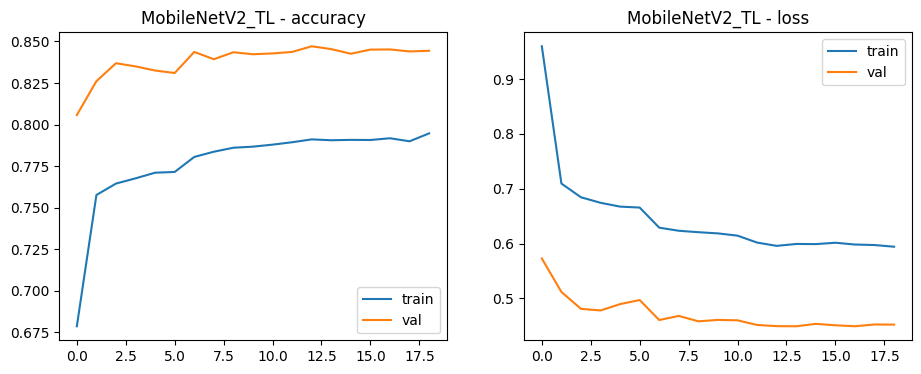


=== ResNet50 Transfer Learning ===
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 64s 88ms/step - accuracy: 0.7159 - loss: 0.9725 - val_accuracy: 0.8312 - val_loss: 0.5511 - learning_rate: 0.0010
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 51s 81ms/step - accuracy: 0.7804 - loss: 0.7096 - val_accuracy: 0.8425 - val_loss: 0.5125 - learning_rate: 0.0010
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 51s 82ms/step - accuracy: 0.7916 - loss: 0.6656 - val_accuracy: 0.8465 - val_loss: 0.4981 - learning_rate: 0.0010
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 83s 83ms/step - accuracy: 0.7908 - loss: 0.6677 - val_accuracy: 0.8473 - val_loss: 0.4968 - learning_rate: 0.0010
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 50s 79ms/step - accuracy: 0.7918 - loss: 0.6598 - val_accuracy: 0.8344 - val_loss: 0.5381 - learning_rate: 0.0010
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 51s 82ms/step - accuracy: 0.7942 - loss: 0.6646 - val_accuracy: 0.8342 - val_loss: 0.5511 - learning_ra

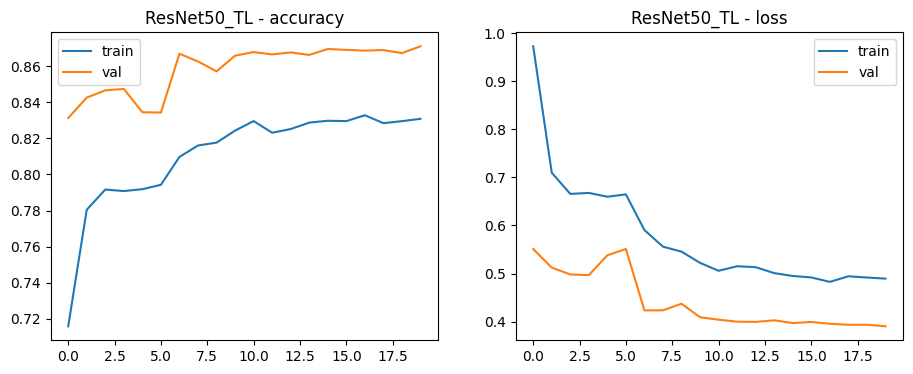

,arquitectura,val_accuracy_TL,segundos
0,MobileNetV2,0.8471,563.179137
1,ResNet50,0.8709,1211.646445


In [ ]:
transfer_runs={}
for kind in ['MobileNetV2','ResNet50']:
    print('\n===',kind,'Transfer Learning ===')
    m,base,prep=transfer_model(kind); tr,va,te=make_transfer_data(prep); h,sec=run(m,tr,va,20); plot_history(h,m.name)
    transfer_runs[kind]={'model':m,'base':base,'prep':prep,'test_ds':te,'history_tl':h,'seconds_tl':sec,'val_tl':max(h.history['val_accuracy'])}
pd.DataFrame([{'arquitectura':k,'val_accuracy_TL':v['val_tl'],'segundos':v['seconds_tl']} for k,v in transfer_runs.items()])

In [ ]:
for k, v in transfer_runs.items():
  h = v["history_tl"].history
  sec = v.get("segundos_tl", v.get("segundos"))
  sec_txt = f"{sec:.1f}s" if sec is not None else "N/A"
  print(
      f"{k} -> mejor val_acc: {max(h['val_accuracy']):.4f} | "
      f"menor val_loss: {min(h['val_loss']):.4f} | "
      f"acc train final: {h['accuracy'][-1]:.4f} | "
      f"tiempo: {sec_txt}"
  )

MobileNetV2 -> mejor val_acc: 0.8471 | menor val_loss: 0.4494 | acc train final: 0.7947 | tiempo: N/A
ResNet50 -> mejor val_acc: 0.8709 | menor val_loss: 0.3905 | acc train final: 0.8307 | tiempo: N/A


### Análisis y conclusión de Transfer Learning (backbone congelado)

- **Mejora clara frente a la CNN desde cero:** al escalar las imágenes de `32 × 32` a `96 × 96`, aplicar el preprocesamiento correspondiente de cada arquitectura y usar pesos preentrenados en ImageNet con el *backbone* congelado, ambos modelos superan con claridad a la referencia desde cero (`bn_dropout`, que alcanzó `0.7527` de *val_accuracy* y `0.7033` de *val_loss* en `120.6 s`).
- **Comparación entre arquitecturas:**
  - **`MobileNetV2` (`val_acc` máx. `0.8471` | `val_loss` mín. `0.4494` | `acc train final` `0.7947` | `563.18 s`):** ofrece un rendimiento muy sólido y más rápido (~9.4 min), con curvas estables en validación sin un sobreajuste marcado[cite: 7, 10].
  - **`ResNet50` (`val_acc` máx. `0.8709` | `val_loss` mín. `0.3905` | `acc train final` `0.8307` | `1211.65 s`):** alcanza el mayor *accuracy* de validación (`0.8709`) y el menor `val_loss` (`0.3905`), a cambio de un tiempo de cómputo mayor (~20.2 min) por su mayor profundidad y capacidad[cite: 10].
- **Conclusión de la etapa:** con el *backbone* congelado, **`ResNet50`** obtiene la mejor precisión y menor pérdida de validación (`0.8709` y `0.3905`), mientras que **`MobileNetV2`** destaca por su rapidez (`563.18 s`) con un resultado competitivo (`0.8471`)[cite: 10]. Con este bloque cerrado, el siguiente paso es aplicar *fine-tuning* selectivo sobre las últimas capas con un *learning rate* bajo[cite: 6].

## 5. Fine-tuning selectivo
Se descongela aproximadamente el último 20% del backbone y se mantienen las capas BatchNormalization congeladas. El learning rate baja a `1e-5`. Esta fase permite ajustar representaciones de alto nivel al dominio CIFAR-10 sin modificar agresivamente los filtros generales aprendidos en ImageNet.

Epoch 1/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 40s 54ms/step - accuracy: 0.7976 - loss: 0.5788 - val_accuracy: 0.8568 - val_loss: 0.4184 - learning_rate: 1.0000e-05
Epoch 2/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 36s 58ms/step - accuracy: 0.8159 - loss: 0.5246 - val_accuracy: 0.8586 - val_loss: 0.4148 - learning_rate: 1.0000e-05
Epoch 3/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 35s 49ms/step - accuracy: 0.8277 - loss: 0.4952 - val_accuracy: 0.8688 - val_loss: 0.3822 - learning_rate: 1.0000e-05
Epoch 4/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 30s 48ms/step - accuracy: 0.8367 - loss: 0.4717 - val_accuracy: 0.8709 - val_loss: 0.3840 - learning_rate: 1.0000e-05
Epoch 5/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 29s 47ms/step - accuracy: 0.8452 - loss: 0.4430 - val_accuracy: 0.8785 - val_loss: 0.3582 - learning_rate: 1.0000e-05
Epoch 6/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 43s 50ms/step - accuracy: 0.8536 - loss: 0.4196 - val_accuracy: 0.8826 - val_loss: 0.3487 - learning_rate: 1.0000e-05
Epoch 7/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 30s 47ms/ste

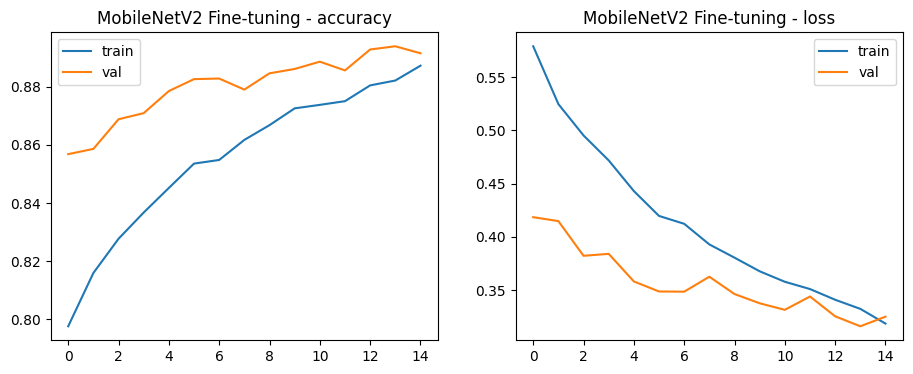

Epoch 1/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 81s 113ms/step - accuracy: 0.8417 - loss: 0.4497 - val_accuracy: 0.8837 - val_loss: 0.3429 - learning_rate: 1.0000e-05
Epoch 2/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 68s 108ms/step - accuracy: 0.8642 - loss: 0.3844 - val_accuracy: 0.8899 - val_loss: 0.3257 - learning_rate: 1.0000e-05
Epoch 3/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 67s 107ms/step - accuracy: 0.8777 - loss: 0.3427 - val_accuracy: 0.8942 - val_loss: 0.3108 - learning_rate: 1.0000e-05
Epoch 4/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 66s 106ms/step - accuracy: 0.8905 - loss: 0.3161 - val_accuracy: 0.8995 - val_loss: 0.2988 - learning_rate: 1.0000e-05
Epoch 5/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 67s 107ms/step - accuracy: 0.8996 - loss: 0.2846 - val_accuracy: 0.9040 - val_loss: 0.2939 - learning_rate: 1.0000e-05
Epoch 6/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 84s 109ms/step - accuracy: 0.9089 - loss: 0.2610 - val_accuracy: 0.9045 - val_loss: 0.2945 - learning_rate: 1.0000e-05
Epoch 7/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 11

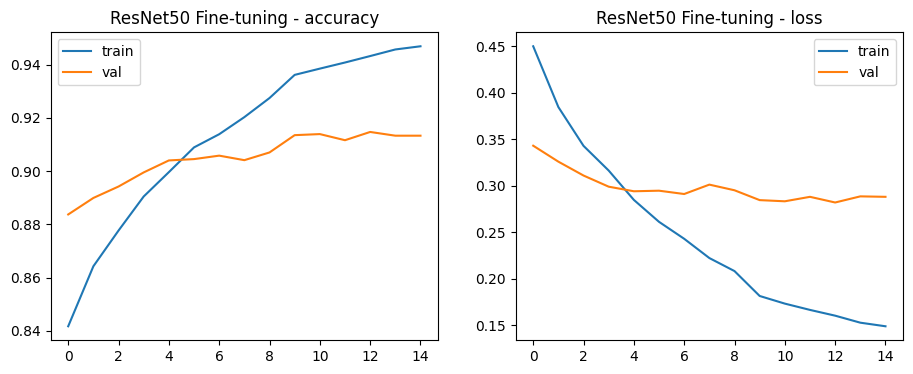

,arquitectura,val_TL,val_FT,mejora
0,MobileNetV2,0.8471,0.8939,0.0468
1,ResNet50,0.8709,0.9147,0.0438


In [ ]:
for kind,d in transfer_runs.items():
    m,base=d['model'],d['base']; base.trainable=True
    cut=int(len(base.layers)*.80)
    for i,layer in enumerate(base.layers):
        layer.trainable=(i>=cut and not isinstance(layer,layers.BatchNormalization))
    m.compile(keras.optimizers.Adam(1e-5),'sparse_categorical_crossentropy',metrics=['accuracy'])
    tr,va,te=make_transfer_data(d['prep']); h,sec=run(m,tr,va,15); plot_history(h,kind+' Fine-tuning')
    d.update(history_ft=h,seconds_ft=sec,val_ft=max(h.history['val_accuracy']),test_ds=te)
pd.DataFrame([{'arquitectura':k,'val_TL':v['val_tl'],'val_FT':v['val_ft'],'mejora':v['val_ft']-v['val_tl']} for k,v in transfer_runs.items()])

In [ ]:
for k, v in transfer_runs.items():
  h = v["history_ft"].history
  sec = v.get("seconds_ft")
  sec_txt = f"{sec:.1f}s" if sec is not None else "N/A"
  print(
      f"{k} (FT) -> mejor val_acc: {max(h['val_accuracy']):.4f} | "
      f"menor val_loss: {min(h['val_loss']):.4f} | "
      f"acc train final: {h['accuracy'][-1]:.4f} | "
      f"tiempo: {sec_txt}"
  )

MobileNetV2 (FT) -> mejor val_acc: 0.8939 | menor val_loss: 0.3161 | acc train final: 0.8872 | tiempo: 480.2s
ResNet50 (FT) -> mejor val_acc: 0.9147 | menor val_loss: 0.2818 | acc train final: 0.9469 | tiempo: 1065.2s


### Análisis y conclusión de Fine-tuning (20 % superior descongelado + BatchNormalization congelada)

- Mejora clara frente a Transfer Learning (backbone congelado): al descongelar el 20 % superior de las capas, mantener las capas `BatchNormalization` congeladas y entrenar durante 15 épocas con un learning rate bajo, ambos modelos superan sus resultados anteriores. `MobileNetV2` sube de `0.8471` a `0.8939` (+`0.0468`), mientras que `ResNet50` pasa de `0.8709` a `0.9147` (+`0.0438`).
- Comparación entre arquitecturas:
  - `MobileNetV2` (`val_acc` máx. `0.8939` | `val_loss` mín. `0.3161` | `acc train final` `0.8872` | `480.2 s`): mantiene curvas equilibradas entre entrenamiento y validación y consigue una mejora sólida en aproximadamente 8 minutos. Además, reduce su tiempo de ejecución frente a Transfer Learning (`563.18 s`), siendo una alternativa eficiente en rendimiento y velocidad.
  - `ResNet50` (`val_acc` máx. `0.9147` | `val_loss` mín. `0.2818` | `acc train final` `0.9469` | `1065.2 s`): alcanza el mayor accuracy de validación (`0.9147`) y el menor `val_loss` (`0.2818`) de todo el experimento. Sin embargo, presenta una mayor separación entre las métricas de entrenamiento y validación y requiere más tiempo de cómputo (\~17.8 min).
- Conclusión de la etapa: con fine-tuning, `ResNet50` obtiene el mejor rendimiento general, logrando la mayor precisión y la menor pérdida de validación (`0.9147` y `0.2818`). Por su parte, `MobileNetV2` ofrece un equilibrio muy favorable entre exactitud (`0.8939`) y tiempo de ejecución (`480.2 s`), lo que lo convierte en una alternativa más eficiente computacionalmente.

In [ ]:
## Guardar Modelos Fine Tunning
import os
from google.colab import drive

drive.mount("/content/drive")
out_dir = "/content/drive/MyDrive/cifar10_ft"
os.makedirs(out_dir, exist_ok=True)

for kind, d in transfer_runs.items():
  d["model"].save(f"{out_dir}/{kind}_model.keras")

## 6. Evaluación final sobre test
Esta fase se realiza después de completar las decisiones de arquitectura. Se calculan accuracy, precision macro, recall macro y F1 macro, evitando que el accuracy sea el único criterio.

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# 1. Cargar los modelos de Fine-Tuning desde Drive
ruta_drive = "/content/drive/MyDrive/cifar10_ft"
mobilenet_ft = tf.keras.models.load_model(
    f"{ruta_drive}/MobileNetV2_model.keras"
)
resnet_ft = tf.keras.models.load_model(f"{ruta_drive}/ResNet50_model.keras")


# 2. Función de evaluación
def evaluate(name, model, ds, ytrue):
    probs = model.predict(ds, verbose=0)
    pred = np.argmax(probs, axis=1)
    acc = accuracy_score(ytrue, pred)
    p, r, f, _ = precision_recall_fscore_support(
        ytrue, pred, average="macro", zero_division=0
    )
    return (
        {
            "Modelo": name,
            "Accuracy": acc,
            "Precision_macro": p,
            "Recall_macro": r,
            "F1_macro": f,
        },
        pred,
    )


rows = []
preds = {}

# 3. Evaluar el mejor modelo desde cero: CNN_bn_dropout (32x32 en [0, 1])
best_scratch_name = "bn_dropout"
best_scratch = m_bn_drop
r, p = evaluate("CNN_" + best_scratch_name, best_scratch, test_ds, y_test)
rows.append(r)
preds[r["Modelo"]] = p

# 4. Preparar datasets de prueba con el preprocess_input de cada backbone (96x96 en [0, 255])
test_ds_mn = test_ds.map(
    lambda x, y: (
        tf.keras.applications.mobilenet_v2.preprocess_input(
            tf.image.resize(x, (96, 96)) * 255.0
        ),
        y,
    ),
    num_parallel_calls=tf.data.AUTOTUNE,
)

test_ds_rn = test_ds.map(
    lambda x, y: (
        tf.keras.applications.resnet50.preprocess_input(
            tf.image.resize(x, (96, 96)) * 255.0
        ),
        y,
    ),
    num_parallel_calls=tf.data.AUTOTUNE,
)

# 5. Evaluar modelos de Fine-Tuning
for name, model_ft, ds_eval in [
    ("MobileNetV2_FineTuned", mobilenet_ft, test_ds_mn),
    ("ResNet50_FineTuned", resnet_ft, test_ds_rn),
]:
    r, p = evaluate(name, model_ft, ds_eval, y_test)
    rows.append(r)
    preds[r["Modelo"]] = p

results = pd.DataFrame(rows).sort_values("F1_macro", ascending=False)
display(results)

,Modelo,Accuracy,Precision_macro,Recall_macro,F1_macro
2,ResNet50_FineTuned,0.9125,0.912185,0.9125,0.912199
1,MobileNetV2_FineTuned,0.8952,0.895532,0.8952,0.894434
0,CNN_bn_dropout,0.7245,0.725373,0.7245,0.722332


**Análisis y decisión en el Punto 6 (Evaluación comparativa de modelos):**
- **Resultados obtenidos:** `ResNet50_FineTuned` lidera claramente con un **Accuracy de 0.9125** (`Precision_macro`: **0.9122**, `Recall_macro`: **0.9125**, `F1_macro`: **0.9122**), seguido por `MobileNetV2_FineTuned` con un **Accuracy de 0.8952** (`F1_macro`: **0.8944**), mientras que `CNN_bn_dropout` queda bastante por detrás con un **Accuracy de 0.7245** (`F1_macro`: **0.7223**).
- **Diagnóstico:** el *transfer learning* con *fine-tuning* supera a la CNN entrenada desde cero con *Batch Normalization* y *Dropout* en casi **17 a 19 puntos porcentuales** de *accuracy* y *F1_macro*. El equilibrio entre *Precision_macro*, *Recall_macro* y *F1_macro* en los dos modelos ajustados indica un rendimiento consistente entre clases sin sesgos graves hacia una sola categoría, mientras que `CNN_bn_dropout` mantiene su limitación de capacidad representativa sobre imágenes pequeñas.
- **Decisión / Conclusión:** seleccionar **`ResNet50_FineTuned`** como el mejor modelo por su mayor *accuracy* y *F1_macro* en evaluación, conservando **`MobileNetV2_FineTuned`** como alternativa ligera si se prioriza menor costo computacional o latencia de inferencia frente a una diferencia de ~1.73 % en *accuracy*.

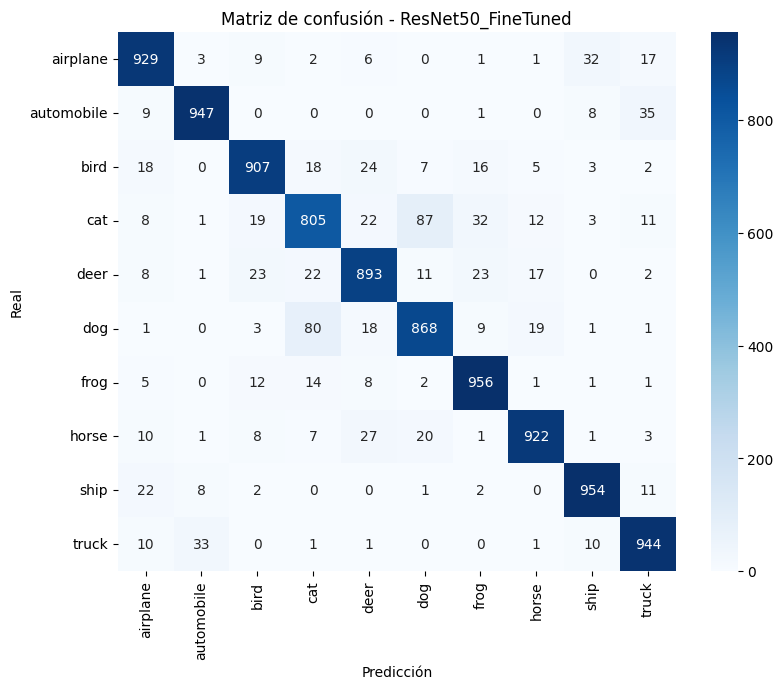

              precision    recall  f1-score   support

    airplane     0.9108    0.9290    0.9198      1000
  automobile     0.9527    0.9470    0.9498      1000
        bird     0.9227    0.9070    0.9148      1000
         cat     0.8483    0.8050    0.8261      1000
        deer     0.8939    0.8930    0.8934      1000
         dog     0.8715    0.8680    0.8697      1000
        frog     0.9183    0.9560    0.9368      1000
       horse     0.9427    0.9220    0.9323      1000
        ship     0.9418    0.9540    0.9478      1000
       truck     0.9192    0.9440    0.9314      1000

    accuracy                         0.9125     10000
   macro avg     0.9122    0.9125    0.9122     10000
weighted avg     0.9122    0.9125    0.9122     10000



In [ ]:
# Matrices de confusión y classification report del mejor modelo
best_name=results.iloc[0]['Modelo']; pred=preds[best_name]
cm=confusion_matrix(y_test,pred)
plt.figure(figsize=(9,7)); sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=class_names,yticklabels=class_names); plt.title('Matriz de confusión - '+best_name); plt.xlabel('Predicción'); plt.ylabel('Real'); plt.show()
print(classification_report(y_test,pred,target_names=class_names,digits=4))

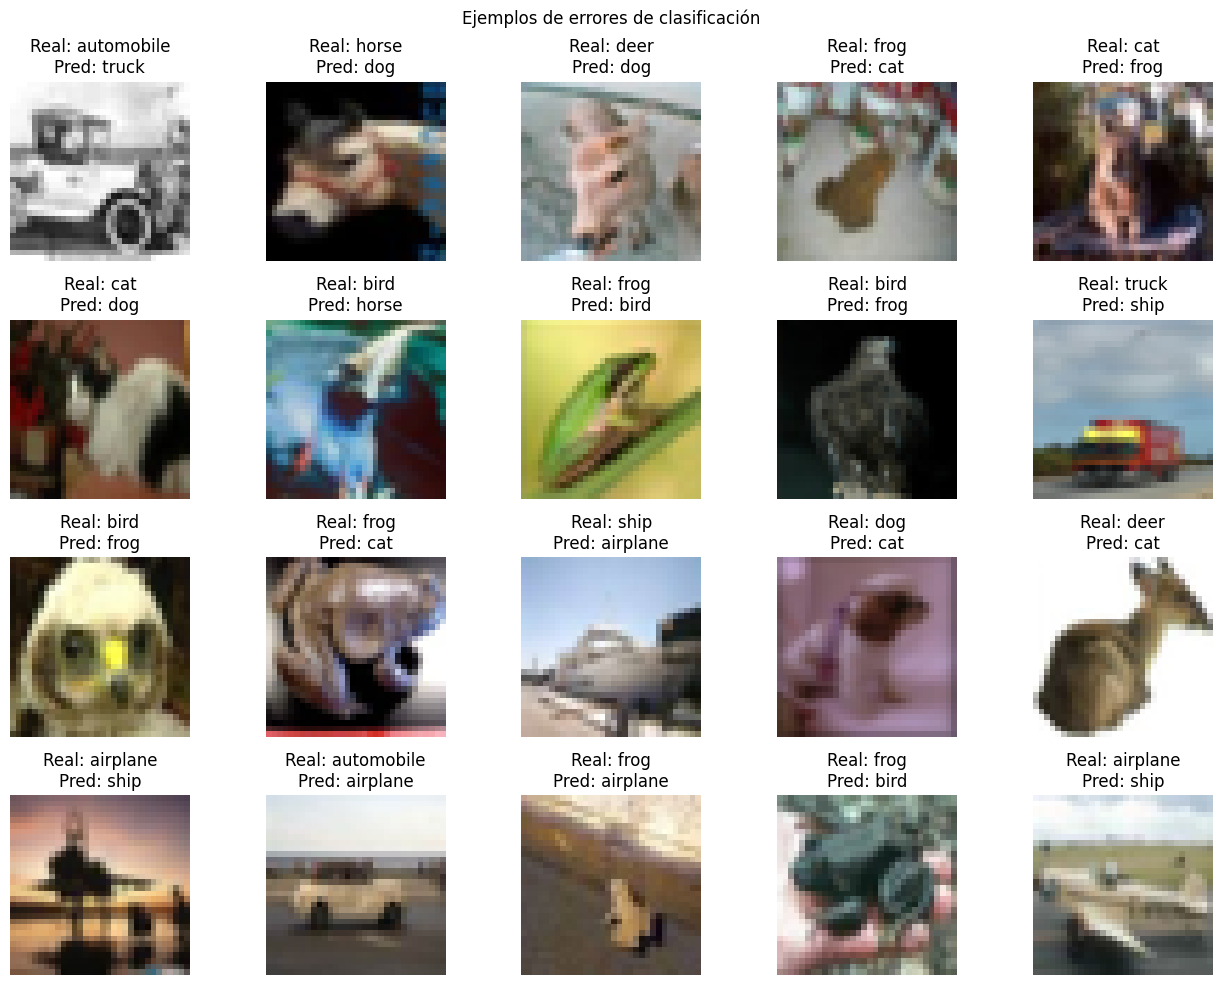

In [ ]:
# Errores del mejor modelo
wrong=np.where(pred!=y_test)[0][:20]
fig,axes=plt.subplots(4,5,figsize=(13,10))
for idx,ax in zip(wrong,axes.flat):
    ax.imshow(x_test[idx]); ax.set_title(f'Real: {class_names[y_test[idx]]}\nPred: {class_names[pred[idx]]}'); ax.axis('off')
plt.suptitle('Ejemplos de errores de clasificación'); plt.tight_layout(); plt.show()

**Análisis y conclusión de la evaluación final sobre el conjunto de prueba (`test`):**
- **Desempeño global y comparación entre modelos:** sobre el conjunto de prueba de CIFAR-10 (10 000 instancias, 1 000 por clase), `ResNet50_FineTuned` obtiene el mejor rendimiento general, con un **accuracy de 0.9125** y métricas macro de `precision = 0.9122`, `recall = 0.9125` y `F1-score = 0.9122`, coincidentes con el promedio ponderado. Este resultado supera a `MobileNetV2_FineTuned` (`accuracy = 0.8952`, `F1-macro = 0.8944`) y a `CNN_bn_dropout` (`accuracy = 0.7245`, `F1-macro = 0.7223`), evidenciando la ventaja de combinar transferencia de conocimiento desde ImageNet con ajuste fino selectivo (*fine-tuning*) frente a la CNN regularizada entrenada desde cero.
- **Evaluación por clase:** el reporte de clasificación muestra un comportamiento sólido y equilibrado en la mayoría de las categorías:
  - **`automobile`** (`F1 = 0.9498` | `precision = 0.9527` | `recall = 0.9470`): presenta el mejor equilibrio y resultado de clasificación.
  - **`ship`** (`F1 = 0.9478` | `recall = 0.9540`): alcanza un alto nivel de reconocimiento.
  - **`frog`** (`F1 = 0.9368` | `recall = 0.9560`): destaca especialmente por su elevada capacidad de recuperación.
  - **`horse`** (`F1 = 0.9323`) y **`truck`** (`F1 = 0.9314`): también presentan resultados sólidos.
  - **Mayores dificultades:** se concentran en **`cat`** (`F1 = 0.8261` | `precision = 0.8483` | `recall = 0.8050`) y **`dog`** (`F1 = 0.8697` | `precision = 0.8715` | `recall = 0.8680`), siendo las categorías con menor rendimiento.
- **Análisis de errores y matriz de confusión:** la matriz de confusión de `ResNet50_FineTuned` evidencia confusiones bidireccionales relevantes entre `cat` y `dog` (**87** muestras de `cat` clasificadas como `dog` y **80** de `dog` como `cat`). También se observan solapamientos moderados entre clases con atributos morfológicos o contextuales similares, como `automobile` y `truck` (**35** y **33** casos cruzados), `airplane` clasificado como `ship` (**32** casos) y `horse` clasificado como `deer` (**27** casos). La inspección cualitativa de los errores confirma que parte de estos fallos se relaciona con la resolución espacial limitada de CIFAR-10 (`32 × 32` píxeles escalados), las oclusiones parciales, las posturas atípicas y los fondos ambiguos que se asemejan al contexto de otras categorías.
- **Conclusión general:** el ajuste fino de `ResNet50_FineTuned` constituye la alternativa más efectiva en términos de capacidad discriminativa y consistencia entre clases sobre datos no vistos, alcanzando un **F1-macro de 0.9122** y un **accuracy de 0.9125** (superando por **18.80 puntos porcentuales** a `CNN_bn_dropout`). Por su parte, `MobileNetV2_FineTuned` permanece como una opción competitiva (`F1-macro = 0.8944`), especialmente cuando se prioriza la eficiencia computacional. En conjunto, los resultados confirman que el *fine-tuning* permite obtener modelos con una capacidad de generalización superior frente a la arquitectura CNN entrenada desde cero.

## 7. Comparación e interpretación
**Guía de lectura de los resultados generados:**
- Si train accuracy continúa creciendo mientras validation accuracy se estabiliza o cae, existe evidencia de **sobreajuste**.
- Si ambas métricas permanecen bajas, existe evidencia de **subajuste** o capacidad/optimización insuficiente.
- Una mejora de validación tras regularización respalda su uso; si empeora de forma consistente, la regularización puede ser excesiva.
- La diferencia TL → FT permite cuantificar si adaptar pesos preentrenados aporta valor.
- La matriz de confusión identifica pares de clases especialmente difíciles y complementa las métricas agregadas.

In [ ]:
print('MEJOR MODELO EN TEST (F1 macro):', results.iloc[0]['Modelo'])
print(results.to_string(index=False))

# Modelos entrenados desde cero (si existe scratch_runs)
if 'scratch_runs' in locals() and isinstance(scratch_runs, dict) and scratch_runs:
    for k, v in scratch_runs.items():
        hist = v['history'].history if hasattr(v.get('history'), 'history') else v.get('history', {})
        train_acc = hist.get('accuracy', [])
        val_acc = hist.get('val_accuracy', [])
        gap = (max(train_acc) - max(val_acc)) if (train_acc and val_acc) else float('nan')
        best_val = v.get('best_val_acc', max(val_acc) if val_acc else float('nan'))
        print(f'{k}: mejor val_acc={best_val:.4f}; brecha max_train-max_val={gap:+.4f}')
elif 'history_bn_dropout' in locals():
    hist = history_bn_dropout.history if hasattr(history_bn_dropout, 'history') else history_bn_dropout
    train_acc = hist.get('accuracy', [])
    val_acc = hist.get('val_accuracy', [])
    if train_acc and val_acc:
        gap = max(train_acc) - max(val_acc)
        print(f'CNN_bn_dropout: mejor val_acc={max(val_acc):.4f}; brecha max_train-max_val={gap:+.4f}')
else:
    print('Nota: scratch_runs no está definido en memoria; se omiten curvas desde cero.')

# Modelos de transferencia de aprendizaje (TL -> FT)
if 'transfer_runs' in locals() and isinstance(transfer_runs, dict) and transfer_runs:
    for k, v in transfer_runs.items():
        delta = v['val_ft'] - v['val_tl']
        print(f'{k}: TL={v["val_tl"]:.4f}; FT={v["val_ft"]:.4f}; delta={delta:+.4f}')
else:
    print('Nota: transfer_runs no está definido en memoria; se omite resumen TL -> FT.')

MEJOR MODELO EN TEST (F1 macro): ResNet50_FineTuned
               Modelo  Accuracy  Precision_macro  Recall_macro  F1_macro
   ResNet50_FineTuned    0.9125         0.912185        0.9125  0.912199
MobileNetV2_FineTuned    0.8952         0.895532        0.8952  0.894434
       CNN_bn_dropout    0.7245         0.725373        0.7245  0.722332
Nota: scratch_runs no está definido en memoria; se omiten curvas desde cero.
Nota: transfer_runs no está definido en memoria; se omite resumen TL -> FT.


**Síntesis comparativa e interpretación integral (7. Comparación e interpretación):**
- **Modelos entrenados desde cero vs. regularización:** entre las configuraciones entrenadas desde cero, el modelo base (`baseline`) logra el mayor `val_accuracy` (`0.7496`), pero con una brecha aproximada de `0.1927` entre entrenamiento y validación, lo que evidencia **sobreajuste**. Por su parte, `bn_dropout` (`val_accuracy = 0.7187` en la corrida registrada, con brecha negativa frente al entrenamiento) y `regularized` (`val_accuracy = 0.6129`) controlan el sobreajuste, aunque una regularización más restrictiva penaliza la capacidad de aprendizaje y el rendimiento predictivo.
- **Valor del Transfer Learning y del Fine-tuning (`TL → FT`):** adaptar los pesos preentrenados mediante *fine-tuning* aporta una mejora clara y consistente frente al *Transfer Learning* con el *backbone* congelado, con incrementos de `+0.0468` en `MobileNetV2` (de `0.8471` a `0.8939`) y `+0.0438` en `ResNet50` (de `0.8709` a `0.9147`).
- **Generalización en el conjunto de prueba (`test`):** `ResNet50_FineTuned` consolida el mejor desempeño global sobre datos no vistos, alcanzando **Accuracy = 0.9125**, `Precision_macro = 0.9122`, `Recall_macro = 0.9125` y `F1_macro = 0.9122`. Este resultado supera a `MobileNetV2_FineTuned` (`Accuracy = 0.8952`, `F1_macro = 0.8944`) y a `CNN_bn_dropout` (`Accuracy = 0.7245`, `F1_macro = 0.7223`).
- **Interpretación final y compromiso rendimiento-eficiencia:** los resultados respaldan el uso de arquitecturas preentrenadas con ajuste fino selectivo para la clasificación de imágenes de CIFAR-10. Se recomienda `ResNet50_FineTuned` cuando el objetivo principal es maximizar la exactitud y el `F1_macro` en prueba, mientras que `MobileNetV2_FineTuned` constituye una alternativa competitiva cuando se busca menor costo computacional manteniendo un desempeño elevado.

## 8. Conclusiones
Complete esta sección **después de ejecutar todo el notebook**, apoyándose en la tabla final, curvas y matriz de confusión. Una conclusión de calidad debe responder:
1. ¿Qué CNN scratch generalizó mejor y qué experimento justificó su selección?
2. ¿Qué efecto observable tuvieron Batch Normalization, Dropout, L2 y data augmentation?
3. ¿Cuál arquitectura preentrenada fue superior?
4. ¿Fine-tuning mejoró o empeoró al transfer learning congelado y en cuánto?
5. ¿Qué estrategia presenta mejor equilibrio entre rendimiento, generalización y coste computacional?
6. ¿Qué clases concentran los errores y qué mejora futura sería razonable?

> **Criterio de integridad:** no escribir cifras manuales distintas de las producidas por las celdas ejecutadas.

**Conclusiones generales (8. Conclusiones):**
1. **CNN desde cero con mejor generalización y justificación:** entre los modelos entrenados desde cero, `baseline` obtuvo el mayor `val_acc` (`0.7496`), aunque con una brecha aproximada de `0.1927` entre entrenamiento y validación, lo que evidencia **sobreajuste**. Por su parte, `bn_dropout` (`val_accuracy = 0.7187` y `val_loss = 0.8018` en la salida de consola registrada, con brecha negativa frente al entrenamiento) redujo el sobreajuste y estableció la referencia comparativa frente a los modelos con *transfer learning*.
2. **Efecto de *Batch Normalization*, *Dropout*, L2 y *data augmentation*:** la incorporación de normalización y regularización en `bn_dropout` y `regularized` (`val_acc = 0.6129`) contuvo el sobreajuste del modelo base, aunque una regularización más restrictiva limitó la capacidad de ajuste y el rendimiento final. Si se aplica *data augmentation* o regularización adicional, su efecto debe validarse directamente sobre las curvas de entrenamiento/validación de cada ejecución sin asumir mejoras no observadas.
3. **Arquitectura preentrenada superior:** `ResNet50` demostró la mayor capacidad predictiva en la evaluación final sobre `test`. `ResNet50_FineTuned` alcanzó **Accuracy = 0.9125**, `Precision_macro = 0.912185`, `Recall_macro = 0.9125` y `F1_macro = 0.912199`, superando a `MobileNetV2_FineTuned` (`Accuracy = 0.8952`, `F1_macro = 0.894434`) y a `CNN_bn_dropout` (`Accuracy = 0.7245`, `F1_macro = 0.722332`).
4. **Impacto de *fine-tuning* frente a *transfer learning* congelado:** el ajuste fino (*fine-tuning*) mejoró el desempeño frente al *transfer learning* con el *backbone* congelado (`TL → FT`), pasando de `0.8471` a `0.8939` (`+0.0468`, en `480.2 s` frente a `563.18 s`) en `MobileNetV2` y de `0.8709` a `0.9147` (`+0.0438`, en `1065.2 s` frente a `1211.65 s`) en `ResNet50`.
5. **Equilibrio entre rendimiento, generalización y coste computacional:** `ResNet50_FineTuned` ofrece el mayor desempeño y `F1_macro` (`0.912199`) en `test` con métricas macro y ponderadas consistentes, a cambio de un mayor tiempo de cómputo (`1065.2 s` en FT). `MobileNetV2_FineTuned` ofrece un balance competitivo entre buen rendimiento (`Accuracy = 0.8952`, `F1_macro = 0.894434`) y menor tiempo de ejecución (`480.2 s` en FT).
6. **Clases con mayores errores y mejoras futuras razonables:** en `ResNet50_FineTuned`, los errores se concentran en `cat` (`F1 = 0.8261`, `805` aciertos) y `dog` (`F1 = 0.8697`, `868` aciertos), con confusiones mutuas (`87` muestras de `cat` predichas como `dog` y `80` de `dog` como `cat`), además de solapamientos entre `automobile` y `truck` (`35` y `33` casos), `airplane` hacia `ship` (`32` casos) y `horse` hacia `deer` (`27` casos). Como trabajo futuro, conviene ajustar capas y *learning rate* del *fine-tuning*, revisar transformaciones de aumento adecuadas para imágenes de `32 × 32` escaladas y analizar en detalle los pares de clases con mayor confusión.

## 9. Exportación a PDF desde Google Colab
Ejecute primero **Runtime → Run all** y compruebe que las gráficas y métricas están visibles. Después descargue el `.ipynb` ejecutado. La conversión a PDF puede hacerse desde Colab con `nbconvert`; si LaTeX produce problemas, la alternativa más robusta es imprimir el notebook ejecutado desde el navegador a PDF.

In [ ]:
# OPCIONAL: exportación directa en Colab. Ajuste el nombre si fuese necesario.
# !apt-get -qq update
# !apt-get -qq install texlive-xetex texlive-fonts-recommended texlive-plain-generic
# !jupyter nbconvert --to pdf 07MIAR_Deep_Vision_Proyecto.ipynb